# `pywccf` samples

How to build and use the sample classes:

1. helpers — `Mesh`, `Log`
2. discrete tracers — `HaloSample`, `SubhaloSample`, `GalaxySample` (columns, selections, hosts, io)
3. tracer → field — NGP / CIC / TSC, number- or mass-weighted (`Tracer.to_field`)
4. fields — `MatterField`, `GasField` (interpolation, smoothing, field → weighted nodes)
5. `TidalField` — tidal tensor from a density, T-web classification, eigenframes, file io

Everything runs on a synthetic box (`pywccf.utils.synthetic_box`); the last cell shows how to load the ELUCID files instead.

In [1]:
import sys
from pathlib import Path
try:
    import pywccf
except ImportError:                       # not installed: use the repository copy
    sys.path.insert(0, str(Path.cwd().parent / 'src'))
    import pywccf

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    'font.size': 13, 'axes.labelsize': 15, 'axes.titlesize': 14, 'legend.fontsize': 12,
    'axes.linewidth': 1.6, 'legend.frameon': False,
    'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True,
    'xtick.minor.visible': True, 'ytick.minor.visible': True,
    'xtick.major.size': 6, 'ytick.major.size': 6, 'xtick.minor.size': 3, 'ytick.minor.size': 3,
    'xtick.major.width': 1.3, 'ytick.major.width': 1.3,
})

def grid(*axes):
    """Major-tick grid only (line plots)."""
    for ax in axes:
        ax.grid(True, which='major', alpha=0.25, lw=0.7)
        ax.grid(False, which='minor')

def top_legend(fig, handles, labels, ncol=None):
    """Figure legend above the panels, in one row."""
    fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, 1.0),
               ncol=ncol or len(labels), frameon=False)

print('pywccf', pywccf.__version__)

pywccf 0.2.0


## 1. Helpers

`Mesh` is a periodic cube of $N^3$ nodes; the value of node $(i,j,k)$ sits at $\mathbf{x}=(i,j,k)\,L/N$ and a point belongs (NGP) to the nearest node. `Log` / `HasLog` print `[ClassName] message` when `verbose=True`.

In [2]:
from pywccf.core import Mesh, Log

mesh = Mesh(n_grids=64, l_box=128.0)
print(mesh, '| cell size =', mesh.l_grid, 'h^-1 Mpc')

xs = np.array([[0.4, 1.1, 127.9], [64.0, 64.9, 65.1]])
print('nearest node :', mesh.x_to_index(xs).tolist())
print('node position:', mesh.index_to_x(mesh.x_to_index(xs)).tolist())
print('jackknife sub-cube (4^3):', mesh.region_of(xs, 4))

log = Log('demo')
log('messages look like this')
with log.timer('a short task'):
    np.linalg.eigh(np.random.default_rng(0).normal(size=(10_000, 3, 3)))

Mesh(n_grids=64, l_box=128) | cell size = 2.0 h^-1 Mpc
nearest node : [[0, 1, 0], [32, 32, 33]]
node position: [[0.0, 2.0, 0.0], [64.0, 64.0, 66.0]]
jackknife sub-cube (4^3): [ 3 42]
[demo] messages look like this


[demo] a short task: 0.01 s


## 2. Discrete tracers

A tracer is a column table: a `dict` of equal-length arrays. Conventions: positions in `position` (N, 3) (or `x`, `y`, `z`) in $h^{-1}{\rm Mpc}$; `mass` is $\log(M/h^{-1}{\rm M_\odot})$ (pass `log_mass=False` for linear masses).

The synthetic box below is a log-normal density field with Poisson-sampled halos whose formation redshift $z_{\rm f}$ is higher in denser regions at fixed mass.

In [3]:
from pywccf.utils import synthetic_box

matter, tidal, halos = synthetic_box(n_grids=64, l_box=128.0, n_halos=40_000, R_s=2.0, seed=0)
print(halos)
print('positions', halos.positions.shape, '| log M_h range:', halos.log_masses.min().round(2), '-', halos.log_masses.max().round(2))
print('number density:', round(halos.number_density(), 4), '(h^-1 Mpc)^-3')

HaloSample(n_objs=40,119, keys=('position', 'mass', 'zf', 'is_backsplash', 'halo_id'))
positions (40119, 3) | log M_h range: 11.5 - 14.0
number density: 0.0191 (h^-1 Mpc)^-3


Building a sample from your own arrays, adding columns, selections:

In [4]:
from pywccf import HaloSample

rng = np.random.default_rng(1)
toy = HaloSample({'position': rng.uniform(0, 128, (1000, 3)),
                  'mass': rng.uniform(11.5, 14.0, 1000),
                  'zf': rng.uniform(0.2, 3.0, 1000)},
                 l_box=128.0, verbose=False)
toy['R200m'] = 0.1 * (10 ** (toy['mass'] - 12)) ** (1 / 3)          # new column
toy.add_property(lambda s: {'log_R200m': np.log10(s['R200m'])})     # or through a function

massive = toy.subset_by_val('mass', lo=13.0)                         # 13 <= log M_h
mid     = toy.subset_by_val('mass', lo=12.0, hi=12.5)                # [12, 12.5)
top10   = toy.subset_by_p('zf', p_lo=0.9)                            # top 10% in z_f
print(len(massive), len(mid), len(top10), type(mid).__name__)
print('counts per 0.5-dex bin:', toy.count_mass_bins([11.5, 12, 12.5, 13, 13.5, 14]))

411 194 100 HaloSample
counts per 0.5-dex bin: [204 194 191 205 206]


**Old / young halos at fixed mass.** `quantile_masks` returns two boolean masks over the sample: the lower and upper `p` tails of a property, computed *inside each bin* of another one. These masks (not new samples) are what the WCCF estimators take, so that all sub-samples share one pair-counting pass.

old: 7,900   young: 7,900   (of 40,119)


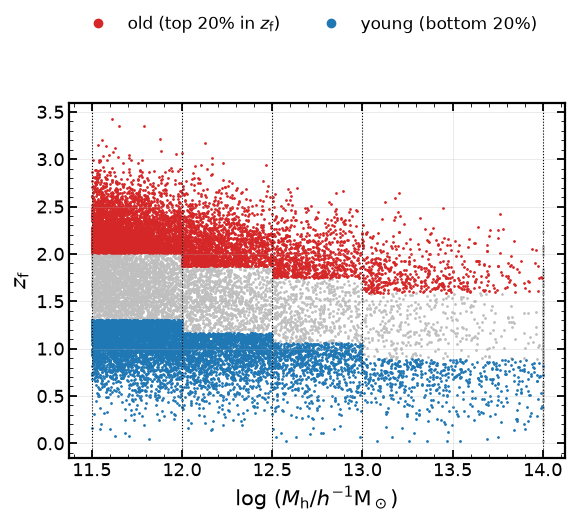

In [5]:
edges = np.array([11.5, 12.0, 12.5, 13.0, 14.0])
young, old = halos.quantile_masks('zf', p=0.2, bin_key='mass', bin_edges=edges)
print(f'old: {old.sum():,}   young: {young.sum():,}   (of {len(halos):,})')

fig, ax = plt.subplots(figsize=(6.4, 4.6))
m, rest = halos.log_masses, ~(old | young)
ax.scatter(m[rest][::5], halos['zf'][rest][::5], s=1, c='0.75', rasterized=True)
h1 = ax.scatter(m[old], halos['zf'][old], s=1, c='C3', rasterized=True)
h2 = ax.scatter(m[young], halos['zf'][young], s=1, c='C0', rasterized=True)
for e in edges:
    ax.axvline(e, color='k', lw=0.8, ls=':')
ax.set_xlabel(r'$\log\,(M_{\rm h}/h^{-1}{\rm M_\odot})$'); ax.set_ylabel(r'$z_{\rm f}$')
grid(ax)
top_legend(fig, [plt.Line2D([], [], color='C3', marker='o', ls=''), plt.Line2D([], [], color='C0', marker='o', ls='')],
           [r'old (top 20% in $z_{\rm f}$)', 'young (bottom 20%)'])

**Hosted tracers.** `SubhaloSample` follows the SUBFIND/tree convention of CosmicCoreBox: `subhalo_id` and `f_in_grp` (id of the first, central subhalo of the group, used as host id); a subhalo is central iff `f_in_grp == subhalo_id`. `GalaxySample` uses `host_id` and, when present, the flag `is_c`.

Below, every synthetic halo above $10^{12.5}$ gets a central subhalo plus a Poisson number of satellites around it.

In [6]:
from pywccf import SubhaloSample, GalaxySample

rng = np.random.default_rng(2)
big = halos.subset_by_val('mass', lo=12.5)
n_sat = rng.poisson(10 ** (big['mass'] - 12.5))
host = np.repeat(np.arange(len(big)), 1 + n_sat)                    # row of the host halo
is_c = np.concatenate([[True] + [False] * k for k in n_sat])
sub_id = np.arange(len(host)) + 1000
f_in_grp = sub_id[np.flatnonzero(is_c)][host]                       # id of the group's central
pos = big.positions[host] + (~is_c)[:, None] * rng.normal(0, 0.3, (len(host), 3))

subs = SubhaloSample({'position': pos % 128.0, 'subhalo_id': sub_id, 'f_in_grp': f_in_grp,
                      'mass': np.where(is_c, big['mass'][host] - 0.05, 11.0 + rng.random(len(host)))},
                     l_box=128.0, verbose=False)
print(subs)
print('centrals:', len(subs.centrals()), '| satellites:', len(subs.satellites()))
ids, n_members = subs.n_per_host()
print('largest group:', n_members.max(), 'subhalos')

# host properties of every subhalo (the host table carries the id of its central)
big['halo_id'] = sub_id[np.flatnonzero(is_c)]
subs.attach_host(big, ['mass', 'zf'], host_id_key='halo_id')
print('host_mass of the first rows:', subs['host_mass'][:5].round(2))

SubhaloSample(n_objs=58,441, keys=('position', 'subhalo_id', 'f_in_grp', 'mass'))
centrals: 7561 | satellites: 50880
largest group: 54 subhalos
host_mass of the first rows: [14. 14. 14. 14. 14.]


In [7]:
gals = GalaxySample({'position': subs.positions, 'mass': subs['mass'] - 1.7,
                     'galaxy_id': subs['subhalo_id'], 'host_id': subs['f_in_grp'],
                     'is_c': subs.is_central}, l_box=128.0, verbose=False)
sat = gals.satellites()
print(f'{len(sat):,} satellite galaxies; mean log M* = {sat.log_masses.mean():.2f}')
print('host rows of the first satellites:', sat.host_index(big, host_id_key='halo_id')[:5])

50,880 satellite galaxies; mean log M* = 9.80
host rows of the first satellites: [0 0 0 0 0]


**HDF5 io.** Every top-level dataset is a column; `l_box` is stored as an attribute.

In [8]:
import tempfile
tmp = Path(tempfile.mkdtemp())
toy.to_file(tmp / 'toy_halos.h5')
back = HaloSample.from_file(tmp / 'toy_halos.h5', verbose=False)
print(back, '| l_box =', back.l_box)
print(HaloSample.from_file(tmp / 'toy_halos.h5', keys=['position', 'mass'], verbose=False))   # selected columns

HaloSample(n_objs=1,000, keys=('R200m', 'log_R200m', 'mass', 'position', 'zf')) | l_box = 128.0
HaloSample(n_objs=1,000, keys=('position', 'mass'))


## 3. Tracer → field

`Tracer.to_field(mesh, scheme, weight)` assigns the tracer to the nodes and returns a `MatterField` with `rho` (weight per unit volume) and `delta = rho/<rho> - 1`. Schemes: `'ngp'`, `'cic'`, `'tsc'` (1, 8, 27 nodes per point); weights: `'number'`, `'mass'` (linear mass), a column name, or an array.

ngp        <delta> = -8.3e-17   sigma = 3.87
cic        <delta> = -3.5e-18   sigma = 2.15
tsc        <delta> = -3.5e-18   sigma = 1.74
cic, mass  <delta> = -2.4e-17   sigma = 4.79


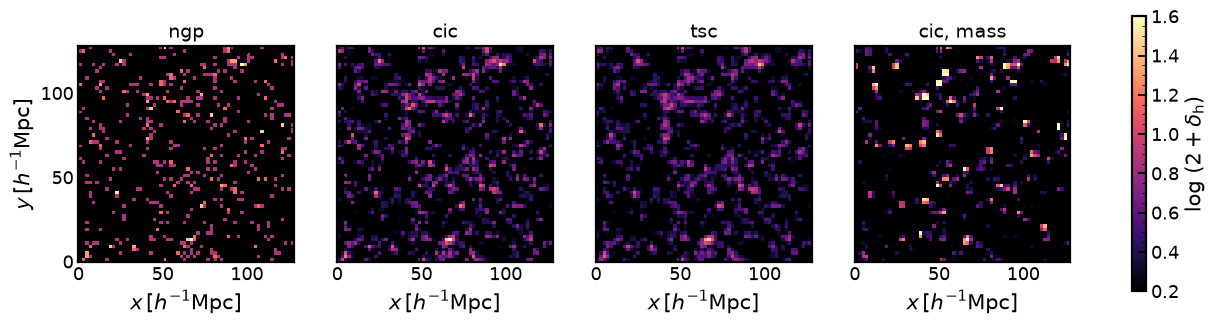

In [9]:
fields = {s: halos.to_field(mesh, scheme=s, weight='number', verbose=False) for s in ('ngp', 'cic', 'tsc')}
fields['cic, mass'] = halos.to_field(mesh, scheme='cic', weight='mass', verbose=False)

fig, axs = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
k = 32
for ax, (name, f) in zip(axs, fields.items()):
    im = ax.imshow(np.log10(2 + f.delta[:, :, k].T), origin='lower', extent=[0, 128, 0, 128],
                   cmap='magma', vmin=0.2, vmax=1.6)
    ax.set_title(name); ax.set_xlabel(r'$x\,[h^{-1}{\rm Mpc}]$')
axs[0].set_ylabel(r'$y\,[h^{-1}{\rm Mpc}]$')
fig.colorbar(im, ax=axs, shrink=0.85, label=r'$\log\,(2+\delta_{\rm h})$')
for name, f in fields.items():
    print(f'{name:10s} <delta> = {f.delta.mean():+.1e}   sigma = {f.delta.std():.2f}')

## 4. Fields

`Field` holds named node arrays on one `Mesh` (plus an optional boolean mask). `MatterField` uses the key `delta`, `GasField` the key `rho`.

In [10]:
print(matter)
xs = halos.positions[:5]
print('delta at halos, NGP:', matter.values_at(xs, scheme='ngp').round(2))
print('delta at halos, CIC:', matter.values_at(xs, scheme='cic').round(2))

d_s = matter.smoothed(R=4.0)                             # Gaussian, R in h^-1 Mpc
print('sigma(delta): raw', matter.delta.std().round(2), '| R = 4:', d_s.std().round(2))

nodes = matter.to_tracer(weight='1+value', stride=2)     # weighted nodes, e.g. for the 3D PH estimator
print(nodes, '| sum of weights:', nodes['weight'].sum().round(1))

MatterField(Mesh(n_grids=64, l_box=128), keys=('delta',))
delta at halos, NGP: [0.21 1.85 2.46 1.55 1.55]
delta at halos, CIC: [0.11 0.64 0.56 1.36 0.61]
sigma(delta): raw 1.31 | R = 4: 0.32
Tracer(n_objs=32,768, keys=('position', 'weight')) | sum of weights: 32936.3


In [11]:
from pywccf import GasField

rho_gas = 0.16 * (1 + matter.smoothed(R=1.0)).clip(1e-3)       # toy gas density
T = 1e4 * (1 + matter.smoothed(R=1.0)).clip(1e-3) ** 0.6       # toy temperature-density relation
gas = GasField({'rho': rho_gas, 'temperature': T}, mesh, verbose=False)
print(gas)
print(f"mass-weighted T = {gas.mass_weighted_mean('temperature'):.3g} K | volume-weighted T = {gas.mean('temperature'):.3g} K")
print('gas delta range:', gas.delta.min().round(2), '-', gas.delta.max().round(2))

GasField(Mesh(n_grids=64, l_box=128), keys=('rho', 'temperature'))
mass-weighted T = 1.26e+04 K | volume-weighted T = 9.46e+03 K
gas delta range: -0.96 - 24.52


## 5. Tidal field

`MatterField.tidal_field(R_s)` (or `TidalField.from_density`) smooths the density with a Gaussian of scale $R_{\rm s}$, solves $\nabla^2\Phi=\delta_{\rm s}$ and diagonalises $T_{ij}=\partial_i\partial_j\Phi$ at every node: eigenvalues `lam` ($\lambda_1\ge\lambda_2\ge\lambda_3$), eigenvectors `evec` (`evec[..., :, m]` $=\mathbf{e}_{m+1}$), smoothed contrast `delta`. The web type is the number of eigenvalues $\ge\lambda_{\rm th}$.

In [12]:
tf = matter.tidal_field(R_s=2.0, lam_th=0.0)
print('trace(T) = delta_s:', np.allclose(tf.lams.sum(-1), tf.delta, atol=1e-4))
print('volume fractions:', {k: round(v, 3) for k, v in tf.volume_fractions().items()})
for th in (-0.2, 0.2):
    print(f'lambda_th = {th:+.1f}:', {k: round(v, 3) for k, v in tf.with_threshold(th).volume_fractions().items()})

web_of_halo = tf.web_type_at(halos.positions)            # 0 void ... 3 knot
print('fraction of halos per web type:', dict(zip(pywccf.WEB_TYPES, (np.bincount(web_of_halo, minlength=4) / len(halos)).round(3))))

trace(T) = delta_s: True
volume fractions: {'void': np.float64(0.089), 'sheet': np.float64(0.454), 'filament': np.float64(0.402), 'knot': np.float64(0.056)}
lambda_th = -0.2: {'void': np.float64(0.0), 'sheet': np.float64(0.063), 'filament': np.float64(0.667), 'knot': np.float64(0.27)}
lambda_th = +0.2: {'void': np.float64(0.484), 'sheet': np.float64(0.369), 'filament': np.float64(0.134), 'knot': np.float64(0.013)}
fraction of halos per web type: {'void': np.float64(0.014), 'sheet': np.float64(0.19), 'filament': np.float64(0.502), 'knot': np.float64(0.295)}


Text(0.5, 1.0, 'T-web, $R_{\\rm s}=2$, $\\lambda_{\\rm th}=0$')

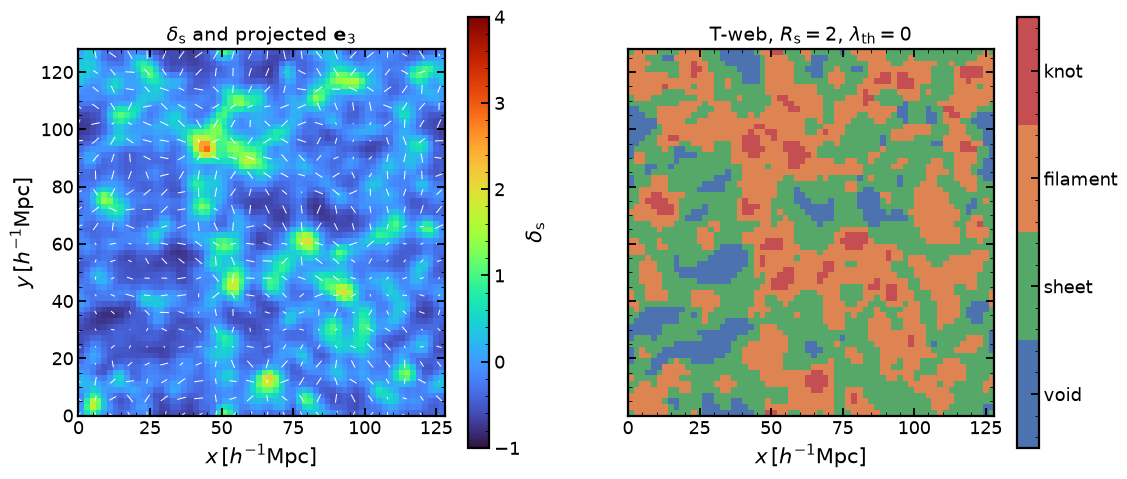

In [13]:
from matplotlib.colors import ListedColormap

k, step = 32, 3
e3 = tf.evecs[::step, ::step, k, :, 2]                   # least-compressing direction
g = np.arange(0, 64, step) * mesh.l_grid
fig, axs = plt.subplots(1, 2, figsize=(13, 5.6), sharey=True)
im = axs[0].imshow(tf.delta[:, :, k].T, origin='lower', extent=[0, 128, 0, 128], cmap='turbo', vmin=-1, vmax=4)
axs[0].quiver(g[:, None] * np.ones_like(g), np.ones_like(g)[:, None] * g, e3[..., 0], e3[..., 1],
              color='w', angles='xy', pivot='mid', headwidth=0, headlength=0, headaxislength=0, scale=40)
fig.colorbar(im, ax=axs[0], label=r'$\delta_{\rm s}$')
im2 = axs[1].imshow(tf.n_lams[:, :, k].T, origin='lower', extent=[0, 128, 0, 128],
                    cmap=ListedColormap(['#4c72b0', '#55a868', '#dd8452', '#c44e52']), vmin=-0.5, vmax=3.5)
cb = fig.colorbar(im2, ax=axs[1], ticks=[0, 1, 2, 3]); cb.ax.set_yticklabels(pywccf.WEB_TYPES)
for ax in axs:
    ax.set_xlabel(r'$x\,[h^{-1}{\rm Mpc}]$')
axs[0].set_ylabel(r'$y\,[h^{-1}{\rm Mpc}]$')
axs[0].set_title(r'$\delta_{\rm s}$ and projected $\mathbf{e}_3$'); axs[1].set_title(r'T-web, $R_{\rm s}=2$, $\lambda_{\rm th}=0$')

**File io.** `to_file` writes the layout of the ELUCID field files (`lam`, `evec`, `delta_sm_x`, `n_grids`, `l_box`, `smoothing_scale`, `lambda_th`). With `load_evec='lazy'` the eigenvectors stay on disk and `evecs_in(mask)` reads only the requested nodes, slab by slab — what the 3D estimator needs on a $500^3$ grid.

In [14]:
path = tf.to_file(tmp / 'field_099.2.hdf5')
tf2 = pywccf.TidalField.from_file(path, load_evec='lazy', verbose=False)
sel = tf2.web_mask('filament')
print('evec in memory:', 'evec' in tf2.data, '| filament eigenframes:', tf2.evecs_in(sel).shape,
      '| identical:', np.allclose(tf2.evecs_in(sel), tf.evecs[sel]))

evec in memory: False | filament eigenframes: (105255, 3, 3) | identical: True


## ELUCID

```python
from pywccf import TidalField, HaloSample

tf = TidalField.from_file('/path/to/ELUCID/field_099.2.hdf5', load_evec='lazy')   # R_s = 2
halos = HaloSample.from_file('/path/to/ELUCID/halo_0701.hdf5', l_box=tf.l_box)
halos = halos.select_paper(zf_range=(0.01, 20.0), exclude_backsplash=True)       # cuts of the paper
```